In [1]:
import pandas as pd

df = pd.read_csv(
    "/content/World_Energy_By_Country_And_Region_1965_to_2023.csv"
)

print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (111, 60)
Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [2]:

# Select India's row
india_row = df[df["Country"] == "India"]

print("India found:", not india_row.empty)

# Display India's original energy consumption data
display(india_row)


India found: True


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
91,India,2.23,2.30,2.37,2.53,2.81,2.75,2.86,3.01,3.07,...,27.59,28.55,29.83,30.96,32.72,33.54,31.78,34.51,36.37,39.02


In [3]:

# Convert India's row into a time-series DataFrame
india_data = india_row.drop(columns=["Country"]).T

# Give the columns clear names
india_data.columns = ["energy_consumption"]

# Convert the year index into a normal column
india_data = india_data.reset_index()

india_data.columns = ["year", "energy_consumption"]

# Convert data types
india_data["year"] = pd.to_numeric(
    india_data["year"], errors="coerce"
)

india_data["energy_consumption"] = pd.to_numeric(
    india_data["energy_consumption"], errors="coerce"
)

# Remove missing values and sort by year
india_data = india_data.dropna()
india_data = india_data.sort_values("year").reset_index(drop=True)

print("India's chronological data:")
display(india_data.head(10))

print("\nLast 5 years:")
display(india_data.tail())


India's chronological data:


,year,energy_consumption
0,1965,2.23
1,1966,2.30
2,1967,2.37
3,1968,2.53
4,1969,2.81
5,1970,2.75
6,1971,2.86
7,1972,3.01
8,1973,3.07
9,1974,3.25



Last 5 years:


,year,energy_consumption
54,2019,33.54
55,2020,31.78
56,2021,34.51
57,2022,36.37
58,2023,39.02


In [5]:

# Check the number of records
print("Total records:", len(india_data))

# Check missing values
print(
    "Missing energy values:",
    india_data["energy_consumption"].isnull().sum()
)

# Check missing years
all_years = set(
    range(
        int(india_data["year"].min()),
        int(india_data["year"].max()) + 1
    )
)

existing_years = set(india_data["year"].astype(int))

missing_years = sorted(all_years - existing_years)

print("Missing years:", missing_years)

# Check duplicate years
print(
    "Duplicate years:",
    india_data["year"].duplicated().sum()
)


Total records: 59
Missing energy values: 0
Missing years: []
Duplicate years: 0


In [6]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Extract energy consumption values
values = india_data["energy_consumption"].values.reshape(-1, 1)

# Split chronologically: first 80% for training
split_index = int(len(values) * 0.80)

# Fit scaler only on the training data
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split_index])

# Normalize all values using the training scaler
scaled_values = scaler.transform(values)

print("Original values (first 5):")
print(values[:5].flatten())

print("\nNormalized values (first 5):")
print(scaled_values[:5].flatten())

print("\nTotal records:", len(scaled_values))
print("Training split index:", split_index)


Original values (first 5):
[2.23 2.3  2.37 2.53 2.81]

Normalized values (first 5):
[0.         0.00325581 0.00651163 0.01395349 0.02697674]

Total records: 59
Training split index: 47


In [7]:

# Create input sequences and target values
X = []
y = []

sequence_length = 5

for i in range(sequence_length, len(scaled_values)):
    # Previous five years
    X.append(scaled_values[i-5:i])

    # Next year's energy consumption
    y.append(scaled_values[i, 0])

# Convert lists into NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst input sequence:")
print(X[0].flatten())

print("\nFirst target:")
print(y[0])


Input shape: (54, 5, 1)
Target shape: (54,)

First input sequence:
[0.         0.00325581 0.00651163 0.01395349 0.02697674]

First target:
0.024186047


In [8]:

# Target years for each sequence
target_indices = np.arange(5, len(scaled_values))

# Use the original chronological 80% split
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

# Split inputs and targets
X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)


Training input shape: (42, 5, 1)
Training target shape: (42,)
Testing input shape: (12, 5, 1)
Testing target shape: (12,)


In [9]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# Create the LSTM model
model = Sequential([
    Input(shape=(5, 1)),

    LSTM(32, activation="tanh"),

    Dense(16, activation="relu"),

    Dense(1)
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:

from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("Model training completed!")


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - loss: 0.0656 - mae: 0.2081 - val_loss: 0.5032 - val_mae: 0.6974
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0580 - mae: 0.1915 - val_loss: 0.4660 - val_mae: 0.6707
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0503 - mae: 0.1732 - val_loss: 0.4254 - val_mae: 0.6402
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0423 - mae: 0.1546 - val_loss: 0.3820 - val_mae: 0.6057
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0324 - mae: 0.1331 - val_loss: 0.3196 - val_mae: 0.5527
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0234 - mae: 0.1148 - val_loss: 0.2564 - val_mae: 0.4935
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0165 - mae: 0.1018 - val_loss: 0.1981 - val_mae: 0.4319
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0119 - mae: 0.0938 - val_loss: 0.1442 - val_mae: 0.3662
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0101 - mae: 

In [15]:

import numpy as np

actual = np.array(y_test_actual)
predicted = np.array(predictions_actual)

# Mean Absolute Percentage Error
mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

# Approximate regression accuracy
accuracy = 100 - mape

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"Approximate accuracy: {accuracy:.2f}%")


MAE: 0.8627
RMSE: 1.1539
MAPE: 2.78%
Approximate accuracy: 97.22%


In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict energy consumption for the test data
predictions_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to original units
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predictions_actual = scaler.inverse_transform(
    predictions_scaled
).flatten()

# Calculate MAE and RMSE
mae = mean_absolute_error(
    y_test_actual,
    predictions_actual
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        predictions_actual
    )
)

print("Model Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


Model Evaluation Results
------------------------
MAE:  0.8627
RMSE: 1.1539


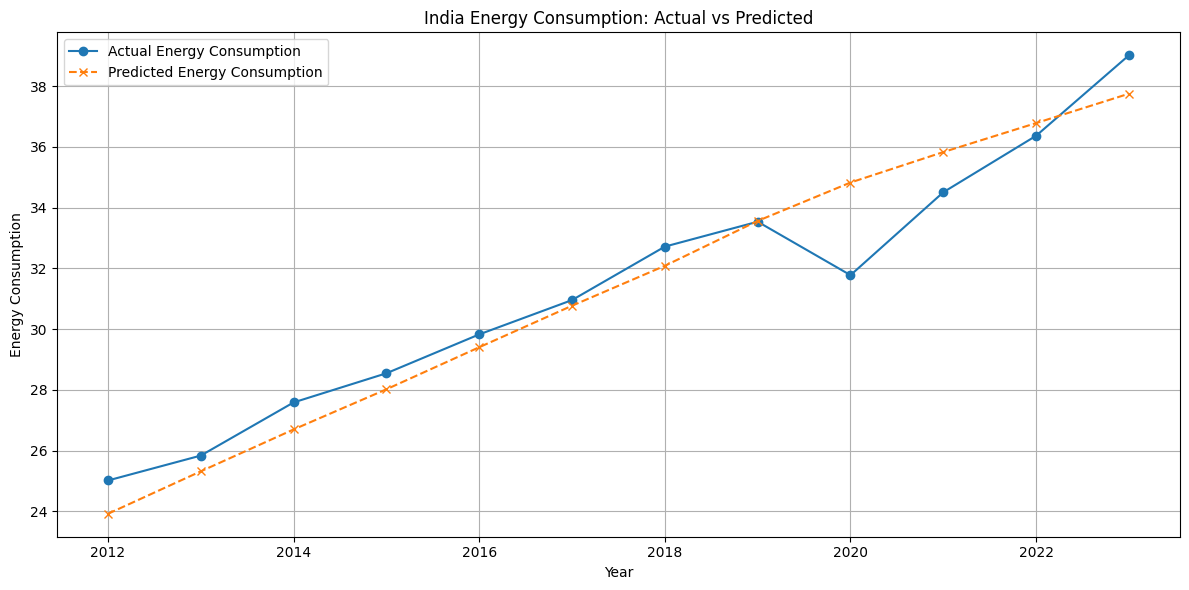

In [13]:

import matplotlib.pyplot as plt

# Get the years corresponding to the test targets
test_years = india_data["year"].to_numpy()[target_indices[test_mask]]

# Plot actual and predicted energy consumption
plt.figure(figsize=(12, 6))

plt.plot(
    test_years,
    y_test_actual,
    marker="o",
    label="Actual Energy Consumption"
)

plt.plot(
    test_years,
    predictions_actual,
    marker="x",
    linestyle="--",
    label="Predicted Energy Consumption"
)

plt.title("India Energy Consumption: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [14]:

# Take the latest five years of observed data
last_five_years = scaled_values[-5:].reshape(1, 5, 1)

# Predict the next year's normalized consumption
next_year_scaled = model.predict(
    last_five_years,
    verbose=0
)

# Convert the prediction back to original units
next_year_consumption = scaler.inverse_transform(
    next_year_scaled
)[0, 0]

# Identify the forecast year
last_year = int(india_data["year"].iloc[-1])
next_year = last_year + 1

print("Last observed year:", last_year)
print("Forecast year:", next_year)
print(
    f"Predicted energy consumption: "
    f"{next_year_consumption:.2f}"
)


Last observed year: 2023
Forecast year: 2024
Predicted energy consumption: 38.64
